In [1]:
# This is needed to prevent kernel crashes due to torch/sklearn conflicts
import os
os.environ['OMP_NUM_THREADS'] = '1'
os.environ['MKL_NUM_THREADS'] = '1'
os.environ['OPENBLAS_NUM_THREADS'] = '1'

In [2]:
import torch, wandb
from torch import nn, optim
import glob
import numpy as np
import matplotlib.pyplot as plt
import yaml
import os
import pandas as pd

from itertools import combinations

import pickle

In [3]:
import os
import sys

# Suppress wandb before any imports that might initialize it
os.environ['WANDB_MODE'] = 'disabled'

REPO = os.path.join(os.getcwd(), "../MULTI-evolve")
sys.path.insert(0, REPO)

import pandas as pd
from Bio import SeqIO

from multievolve.splitters import KFoldProteinSplitter
from multievolve.featurizers import OneHotFeaturizer
from multievolve.predictors import Fcn
from multievolve.proposers import CombinatorialProposer
from multievolve.utils.data_utils import TorchDataProcessor
from multievolve.utils.other_utils import AAs

import argparse

from sklearn.linear_model import LinearRegression

/Users/averma2/miniconda3/envs/multievolve/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [4]:
torch.autograd.grad_mode.set_grad_enabled(False)
if torch.cuda.is_available():
    device = "cuda"
elif torch.backends.mps.is_available():
    device = "mps"
else:
    device = "cpu"
print(f"device: {device}")

device: mps


In [5]:
# PROTEIN = "apex"
PROTEIN = "dcasrx"
# PROTEIN = "huabc2"
MEASUREMENT = "bind"  # only used for huabc2: "expr" or "bind"

N_SPLITS = 10

# Training data lives in output/ (generated by prep_training_data.py)
OUTPUT_DIR = os.path.join(os.getcwd(), '../output', PROTEIN)
DATA_DIR = os.path.join(os.getcwd(), '../data')

if PROTEIN == 'huabc2':
    TRAINING_CSV = os.path.join(OUTPUT_DIR, f'huabc2_training_{MEASUREMENT}_log2.csv')
    WT_FASTA = [
        os.path.join(DATA_DIR, 'huabc2_vh.fasta'),
        os.path.join(DATA_DIR, 'huabc2_vl.fasta'),
    ]
    IS_MULTICHAIN = True
    # Select which cached architecture to use when multiple exist:
    #   '' for 0-layer, '100' for 1×100, '100-100-100-100-100' for 5×100, etc.
    if MEASUREMENT == 'expr':
        ARCH_FILTER = '100-100-100-100-100'
    elif MEASUREMENT == 'bind':
        ARCH_FILTER = '100-100-100'
else:
    TRAINING_CSV = os.path.join(OUTPUT_DIR, f'{PROTEIN}_training_log2.csv')
    WT_FASTA = os.path.join(DATA_DIR, f'{PROTEIN}.fasta')
    IS_MULTICHAIN = False
    ARCH_FILTER = None  # no filtering needed

print(f"PROTEIN: {PROTEIN}")
if PROTEIN == 'huabc2':
    print(f"MEASUREMENT: {MEASUREMENT}")
    print(f"ARCH_FILTER: {ARCH_FILTER!r}")
print(f"IS_MULTICHAIN: {IS_MULTICHAIN}")

PROTEIN: dcasrx
IS_MULTICHAIN: False


# LOAD DATA

### copied directly from "additive-comparison-*.ipynb" in MULTI-EVOLVE/analysis

In [6]:
effect_dictionary = {}

# ── Helper functions for multi-chain notation ──
def parse_chain_muts(mutation_str):
    """Parse 'VH_muts:VL_muts' → (vh_list, vl_list)."""
    parts = mutation_str.split(':')
    vh = [m for m in parts[0].split('/') if m != 'WT']
    vl = [m for m in parts[1].split('/') if m != 'WT']
    return vh, vl

def double_to_singles(double_mut):
    """Convert a double like 'L11Q:Y93W' to its two single-mutation
    chain-notation strings: ('L11Q:WT', 'WT:Y93W')."""
    vh_muts, vl_muts = parse_chain_muts(double_mut)
    singles = []
    for m in vh_muts:
        singles.append(f'{m}:WT')
    for m in vl_muts:
        singles.append(f'WT:{m}')
    return singles

# ── Load data ──
if PROTEIN == 'dcasrx':
    full_df = pd.read_excel('../data/Table S15 dCasRx variants.xlsx')
    MUTANT_COL = 'Mutations'
    LOGFC_COL = 'Fold Improvement (gTSM only)'
    SINGLES_ORIGIN = 'DMS'
    WT_TOKEN = 'WT'
elif PROTEIN == 'apex':
    full_df = pd.read_excel('../data/Table S14 APEX variants.xlsx')
    MUTANT_COL = 'Mutant'
    LOGFC_COL = 'Fold Improvement (75 min)'
    SINGLES_ORIGIN = 'PLM zeroshot'
    WT_TOKEN = 'WT'
elif PROTEIN == 'huabc2':
    full_df = pd.read_excel('../data/Table S16 HuABC2 variants.xlsx')
    MUTANT_COL = 'Mutations'
    if MEASUREMENT == 'expr':
        LOGFC_COL = 'Fold Improvement (Expression)'
    else:
        LOGFC_COL = 'Fold Improvement (Binding)'
    SINGLES_ORIGIN = 'PLM zeroshot'
    WT_TOKEN = 'WT:WT'

full_df = full_df[[x for x in full_df.columns.values if 'Unnamed' not in x]]
full_df['logfc'] = pd.to_numeric(full_df[LOGFC_COL], errors='coerce').apply(np.log2)

# ── Singles ──
singles = full_df[full_df['Origin'].isin(['DMS', 'PLM zeroshot'])].copy()
effect_dictionary['single_effect'] = dict(zip(singles[MUTANT_COL], singles['logfc']))

# ── Doubles ──
doubles = full_df[full_df['Origin'] == 'Double Mutant'].copy()

if PROTEIN == 'huabc2':
    # For multi-chain, decompose each double into its constituent singles
    doubles['muts'] = doubles[MUTANT_COL].apply(double_to_singles)
else:
    doubles['muts'] = doubles[MUTANT_COL].apply(lambda x: x.split('/'))

doubles['single_prediction'] = doubles['muts'].apply(
    lambda x: sum([effect_dictionary['single_effect'].get(i, np.nan) for i in x]))
doubles['epistatic_effect'] = doubles['logfc'] - doubles['single_prediction']
effect_dictionary['epistatic_effect'] = dict(zip(doubles[MUTANT_COL], doubles['epistatic_effect']))

# ── MULTI-evolve variants (targets) ──
df = full_df[full_df['Origin'] == 'MULTI-evolve variant'].copy()
if PROTEIN == 'huabc2':
    df['muts'] = df[MUTANT_COL].apply(double_to_singles)
else:
    df['muts'] = df[MUTANT_COL].apply(lambda x: x.split('/'))

# ── Build single mutation pool ──
if PROTEIN == 'huabc2':
    single_muts_set = set()
    for mut_str in doubles[MUTANT_COL]:
        for s in double_to_singles(mut_str):
            single_muts_set.add(s)
    single_muts = sorted(single_muts_set)
else:
    single_muts = [x.split('/') for x in doubles[MUTANT_COL].unique()]
    single_muts = list(set([item for sublist in single_muts for item in sublist]))

# ── Combinatorial pool ──
if PROTEIN == 'huabc2':
    MUT_COUNTS = [3, 4, 5, 6, 7]
else:
    MUT_COUNTS = [5, 6, 7]

all_muts = []
for i in MUT_COUNTS:
    all_muts.append(pd.DataFrame({'muts': list(combinations(single_muts, i))}).assign(label=f'muts_{i}'))
all_muts = pd.concat(all_muts)

# Remove mutants with multiple subs at one site (impossible)
if PROTEIN == 'huabc2':
    # Extract positions: VH mutations have no prefix, VL are after ':'
    def get_sites(muts_tuple):
        sites = []
        for m in muts_tuple:
            vh, vl = parse_chain_muts(m)
            for s in vh:
                sites.append(('VH', int(s[1:-1])))
            for s in vl:
                sites.append(('VL', int(s[1:-1])))
        return sites
    all_muts['sites'] = all_muts['muts'].apply(get_sites)
    mask = all_muts['sites'].apply(lambda x: len(x) == len(set(x)))
else:
    all_muts['sites'] = all_muts['muts'].apply(lambda x: [int(i[1:-1]) for i in x])
    mask = all_muts['sites'].apply(lambda x: len(x) == len(set(x)))
all_muts = all_muts[mask].copy()

# Make all sub-doubles
all_muts['double_muts'] = all_muts['muts'].apply(
    lambda x: ["/".join(i) if not IS_MULTICHAIN else i[0].split(':')[0] + '/' + i[1].split(':')[0] + ':' + i[0].split(':')[1] + '/' + i[1].split(':')[1]
               for i in list(combinations(x, 2))] if not IS_MULTICHAIN else None)
# For huabc2, double_muts isn't needed in the same way — we skip it
if IS_MULTICHAIN:
    all_muts['double_muts'] = None

# Key for joining
all_muts['muts_s'] = all_muts['muts'].apply(lambda x: str(sorted(x)))
df['muts_s'] = df['muts'].apply(lambda x: str(sorted(x)))
targets = df['muts_s']
print(f"num targets: {len(targets)}")

# ── Merge MULTI-evolve predictions ──
merged = all_muts.copy()
meas_tag = f'_{MEASUREMENT}' if PROTEIN == 'huabc2' else ''
me = pd.read_csv(os.path.join(OUTPUT_DIR, f'{PROTEIN}{meas_tag}_multievolve_proposals.csv'))

if IS_MULTICHAIN:
    # Convert flat/offset Mut_string back to chain-prefixed sorted key
    chain_seqs = [str(SeqIO.read(f, 'fasta').seq.upper()) for f in WT_FASTA]
    VH_LEN = len(chain_seqs[0])

    def flat_offset_to_chain_sorted(mut_string):
        """Convert 'L11Q/F203G' to sorted chain-notation singles list."""
        muts = mut_string.split('/')
        singles = []
        for m in muts:
            pos = int(m[1:-1])
            if pos <= VH_LEN:
                singles.append(f'{m}:WT')
            else:
                orig_pos = pos - VH_LEN
                singles.append(f'WT:{m[0]}{orig_pos}{m[-1]}')
        return str(sorted(singles))

    me['muts_s'] = me['Mut_string'].apply(flat_offset_to_chain_sorted)
else:
    me['muts_s'] = me['Mut_string'].apply(lambda x: str(sorted(x.split('/'))))

me = me[me['num_muts'].between(min(MUT_COUNTS), max(MUT_COUNTS))]
merged = merged.merge(
    me[['muts_s', 'average']].rename(columns={'average': 'multievolve_pred_log2'}),
    on='muts_s', how='inner',
)
print(f'Merged: {len(merged)} rows')

num targets: 9
Merged: 6270 rows


# LOAD LINEAR REGRESSION

In [7]:
def build_onehot(muts_list, mut_to_index, num_muts):
    """One-hot encode a list of mutation strings."""
    X = np.zeros((len(muts_list), num_muts))
    for i, muts in enumerate(muts_list):
        if isinstance(muts, str):
            muts = [muts]
        for mut in muts:
            if IS_MULTICHAIN:
                # Chain notation: decompose 'L11Q:Y93W' → ['L11Q:WT', 'WT:Y93W']
                for s in double_to_singles(mut):
                    if s in mut_to_index:
                        X[i, mut_to_index[s]] = 1.0
            else:
                for m in mut.split('/'):
                    if m in mut_to_index:
                        X[i, mut_to_index[m]] = 1.0
    return X


df_data = pd.read_csv(TRAINING_CSV)
df_data = df_data[df_data['mutation'] != WT_TOKEN]

# Build mutation index from singles only
singles_data = df_data[~df_data['mutation'].str.contains('/')]
mut_to_index = {m: i for i, m in enumerate(singles_data['mutation'])}
num_muts_lr = len(mut_to_index)

# Training data: encode all training variants (singles + doubles)
X_train = build_onehot(df_data['mutation'].values, mut_to_index, num_muts_lr)
y_train = df_data['property_value'].values

# Test data: combinatorial pool
if IS_MULTICHAIN:
    # For multi-chain, each row's muts are already chain-notation singles
    X_test = build_onehot(
        [list(row['muts']) for _, row in merged.iterrows()],
        mut_to_index, num_muts_lr
    )
else:
    X_test = build_onehot(
        [list(row['muts']) + row['double_muts'] for _, row in merged.iterrows()],
        mut_to_index, num_muts_lr
    )

# --- LinearRegression ---
linreg = LinearRegression(fit_intercept=True)
linreg.fit(X_train, y_train)
merged['prediction_additive'] = linreg.predict(X_test)
print(f"Additive (LinearRegression, log2)")

## identify paper variants
tran_merged = merged[merged['muts_s'].isin(targets)]
print(f"\nPaper variants found: {len(tran_merged)} / {len(targets)}")

Additive (LinearRegression, log2)

Paper variants found: 9 / 9


In [8]:
linreg.intercept_

0.447281933218692

# LOAD FCN

In [9]:
# Auto-discover model filenames per split and parse hyperparameters
if PROTEIN == 'huabc2':
    training_stem = f'huabc2_training_{MEASUREMENT}_log2'
else:
    training_stem = f'{PROTEIN}_training_log2'

partial_dir = os.path.join(REPO, f'proteins/{PROTEIN}/model_cache/{training_stem}*/objects/')
matched_dirs = glob.glob(partial_dir)
assert len(matched_dirs) != 0, f"partial directory '{partial_dir}' not matched to anything! Double check whether training_stem and REPO are correct"
cache_dir = matched_dirs[0]
all_files = os.listdir(cache_dir)

# If ARCH_FILTER is set, narrow down to files matching that architecture string
if ARCH_FILTER is not None:
    # Architecture field is between '__ fcn __ ' and the next ' __'
    arch_token = f'__ fcn __ {ARCH_FILTER} __'
    all_files = [f for f in all_files if arch_token in f]
    print(f"Filtered to arch '{ARCH_FILTER}': {len(all_files)} files")

model_paths = []
for split_idx in range(N_SPLITS):
    matches = [f for f in all_files if f.startswith(f"split_by_kfold-{split_idx}_")]
    assert len(matches) == 1, f"Expected 1 file for split {split_idx}, found {len(matches)}: {matches}"
    model_paths.append(os.path.join(cache_dir, matches[0]))

# Parse hyperparameters from split-0 filename
# Format: split_by_kfold-{idx}_{split_ratio}-y_scaled __ onehot __ fcn __ {arch} __ {lr} __ {bs} __ {opt}.pth
parts = [p.strip() for p in os.path.basename(model_paths[0]).split('__')]
arch_str = parts[3]
LEARNING_RATE = float(parts[4])
BATCH_SIZE = int(parts[5])
OPTIMIZER = parts[6].replace('.pth', '')
print(f"Parsed from filename: arch={arch_str}, lr={LEARNING_RATE}, batch_size={BATCH_SIZE}, optimizer={OPTIMIZER}")
print(f"Found {len(model_paths)} model paths")

Parsed from filename: arch=100, lr=0.001, batch_size=32, optimizer=adam
Found 10 model paths


In [10]:
splitter = KFoldProteinSplitter(
    PROTEIN,
    TRAINING_CSV,
    WT_FASTA,
    csv_has_header=True,
    use_cache=False,
    y_scaling=True,
    val_split=0.15,
)
splits = splitter.generate_splits(n_splits=10)

In [11]:
featurizer = OneHotFeaturizer(protein=PROTEIN, use_cache=False)

# Infer num_layers and layer_size from the first checkpoint's state_dict
state_dict = torch.load(model_paths[0], map_location='cpu', weights_only=True)
linear_keys = sorted([k for k in state_dict if k.endswith('.weight') and k.startswith('layers.')])
num_layers = len(linear_keys) - 1  # hidden layers (excluding output)
layer_size = state_dict[linear_keys[0]].shape[0]

CONFIG = {
    'layer_size': layer_size,
    'num_layers': num_layers,
    'learning_rate': LEARNING_RATE,
    'batch_size': BATCH_SIZE,
    'optimizer': OPTIMIZER,
    'epochs': 300,
}
print(f"CONFIG: {num_layers} hidden layer(s), width {layer_size}, lr={LEARNING_RATE}, batch_size={BATCH_SIZE}, optimizer={OPTIMIZER}")

models = []
for split_idx in range(N_SPLITS):
    model = Fcn(splits[split_idx], featurizer, config=CONFIG, use_cache=False, show_plots=False)
    model.load_model(model_paths[split_idx])
    if not hasattr(model, 'train_loader'):
        model.train_loader = model.nn_data_processor.setup_train_loader()
    model.eval()
    models.append(model)

print(f"Loaded {len(models)} models")

CONFIG: 1 hidden layer(s), width 100, lr=0.001, batch_size=32, optimizer=adam
MPS available. Using Apple Silicon GPU for Neural Network.
Loading model from /Users/averma2/Documents/dewitt_lab/code/multievolve-baselines/analysis/../MULTI-evolve/proteins/dcasrx/model_cache/dcasrx_training_log2_ec26cde9/objects/split_by_kfold-0_76-13-10-y_scaled __ onehot __ fcn __ 100 __ 0.001 __ 32 __ adam.pth
Featurizing training data...
MPS available. Using Apple Silicon GPU for Neural Network.
Loading model from /Users/averma2/Documents/dewitt_lab/code/multievolve-baselines/analysis/../MULTI-evolve/proteins/dcasrx/model_cache/dcasrx_training_log2_ec26cde9/objects/split_by_kfold-1_76-13-10-y_scaled __ onehot __ fcn __ 100 __ 0.001 __ 32 __ adam.pth
Featurizing training data...
MPS available. Using Apple Silicon GPU for Neural Network.
Loading model from /Users/averma2/Documents/dewitt_lab/code/multievolve-baselines/analysis/../MULTI-evolve/proteins/dcasrx/model_cache/dcasrx_training_log2_ec26cde9/obje

In [12]:
print(models[0])
print(f"Loss function uses '{models[0].criterion.reduction}' reduction for batches")

Fcn(
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (layers): ModuleList(
    (0): Linear(in_features=21274, out_features=100, bias=True)
    (1): LeakyReLU(negative_slope=0.2)
    (2): Dropout(p=0.2, inplace=False)
    (3): Linear(in_features=100, out_features=1, bias=True)
  )
  (criterion): MSELoss()
)
Loss function uses 'mean' reduction for batches


In [13]:
for split_idx, m in enumerate(models):
    m.eval()
    total_train_loss = 0
    for batch in m.train_loader:
        inputs, gt, __ = batch
        inputs, gt = inputs.to(m.device), gt.to(m.device)
        gt = gt.unsqueeze(1)
        outputs = m(inputs)
        loss = m.criterion(outputs, gt)
        total_train_loss += loss.item()
    avg_loss = total_train_loss / len(m.train_loader)
    print(f"Split {split_idx}: avg_loss = {avg_loss:.6f}")

Split 0: avg_loss = 0.002989
Split 1: avg_loss = 0.003188
Split 2: avg_loss = 0.001581
Split 3: avg_loss = 0.003466
Split 4: avg_loss = 0.004635
Split 5: avg_loss = 0.006635
Split 6: avg_loss = 0.003132
Split 7: avg_loss = 0.002539
Split 8: avg_loss = 0.001767
Split 9: avg_loss = 0.002710


# TESTING

### Re-creating correlation plot

In [14]:
if IS_MULTICHAIN:
    chain_seqs = [str(SeqIO.read(f, 'fasta').seq.upper()) for f in WT_FASTA]
    wt_seq = ''.join(chain_seqs)
    VH_LEN = len(chain_seqs[0])
    VL_LEN = len(chain_seqs[1])
    print(f'VH: {VH_LEN} AA, VL: {VL_LEN} AA, total: {len(wt_seq)} AA')
else:
    wt_seq = models[0].nn_data_processor.X_train[0]

rev_mut_to_index = {v: k for (k, v) in mut_to_index.items()}

In [15]:
def split_mut(mut):
    """Parse a flat mutation string like 'L11Q' → (wt_aa, 1-indexed pos, mut_aa)."""
    return (mut[0], int(mut[1:-1]), mut[-1])


def apply_chain_mutations(chain_mut_str, wt=None, vh_len=None):
    """Apply chain-notation mutations to the concatenated WT sequence.
    e.g. 'L11Q:Y93W' → mutate VH pos 11 and VL pos 93 (offset by vh_len)."""
    if wt is None:
        wt = wt_seq
    if vh_len is None:
        vh_len = VH_LEN
    seq = list(wt)
    vh_muts, vl_muts = parse_chain_muts(chain_mut_str)
    for m in vh_muts:
        wt_aa, pos, mut_aa = m[0], int(m[1:-1]), m[-1]
        assert seq[pos - 1] == wt_aa, \
            f'VH pos {pos}: expected {wt_aa}, got {seq[pos-1]}'
        seq[pos - 1] = mut_aa
    for m in vl_muts:
        wt_aa, pos, mut_aa = m[0], int(m[1:-1]), m[-1]
        idx = vh_len + pos - 1
        assert seq[idx] == wt_aa, \
            f'VL pos {pos} (idx {idx}): expected {wt_aa}, got {seq[idx]}'
        seq[idx] = mut_aa
    return ''.join(seq)

In [16]:
def Ldata_to_NNdata(
    Ldata, # data used for linear regression [batch, total_muts]
    wt_seq, # wild-type seq (concatenated for multi-chain)
    featurizer, # featurizer that takes list[str] of seqs
    rev_mut_to_index=None, # dictionary corresponding to Ldata
):
    if rev_mut_to_index is None:
        rev_mut_to_index_local = globals()['rev_mut_to_index']
    else:
        rev_mut_to_index_local = rev_mut_to_index

    seqs = []
    for i in range(Ldata.shape[0]):
        X = Ldata[i]
        muts = np.argwhere(X)[:, 0]

        if IS_MULTICHAIN:
            # Mutations are in chain notation (e.g. 'L11Q:WT', 'WT:F82G')
            # Apply them all to the WT sequence
            seq = list(wt_seq)
            for m_idx in muts:
                chain_mut = rev_mut_to_index_local[m_idx]
                vh_m, vl_m = parse_chain_muts(chain_mut)
                for m in vh_m:
                    aa1, s_idx, aa2 = m[0], int(m[1:-1]), m[-1]
                    assert seq[s_idx - 1] == aa1
                    seq[s_idx - 1] = aa2
                for m in vl_m:
                    aa1, s_idx, aa2 = m[0], int(m[1:-1]), m[-1]
                    idx = VH_LEN + s_idx - 1
                    assert seq[idx] == aa1
                    seq[idx] = aa2
            seqs.append("".join(seq))
        else:
            n_seq = list(wt_seq)
            for m_idx in muts:
                aa1, s_idx, aa2 = split_mut(rev_mut_to_index_local[m_idx])
                assert n_seq[s_idx - 1] == aa1
                n_seq[s_idx - 1] = aa2
            seqs.append("".join(n_seq))

    return (seqs, featurizer.featurize(seqs))

In [17]:
X_test_seqs, X_test_enc_seqs = Ldata_to_NNdata(X_test, wt_seq, models[0].featurizer)

In [18]:
num_muts_per_seq = np.array(merged["muts"].apply(len))

In [19]:
# Average NN predictions over all splits
X_test_tensor = torch.from_numpy(X_test_enc_seqs).float().to(device)
all_nn_vals = []
for m in models:
    m.eval()
    preds = m(X_test_tensor).squeeze().cpu().numpy()
    all_nn_vals.append(preds)
all_nn_vals = np.stack(all_nn_vals)  # (N_SPLITS, n_variants)
NN_vals = all_nn_vals.mean(axis=0)
NN_vals_std = all_nn_vals.std(axis=0)
print(f"Averaged predictions over {len(models)} splits, shape: {NN_vals.shape}")

linreg_vals = linreg.predict(X_test)

Averaged predictions over 10 splits, shape: (6270,)


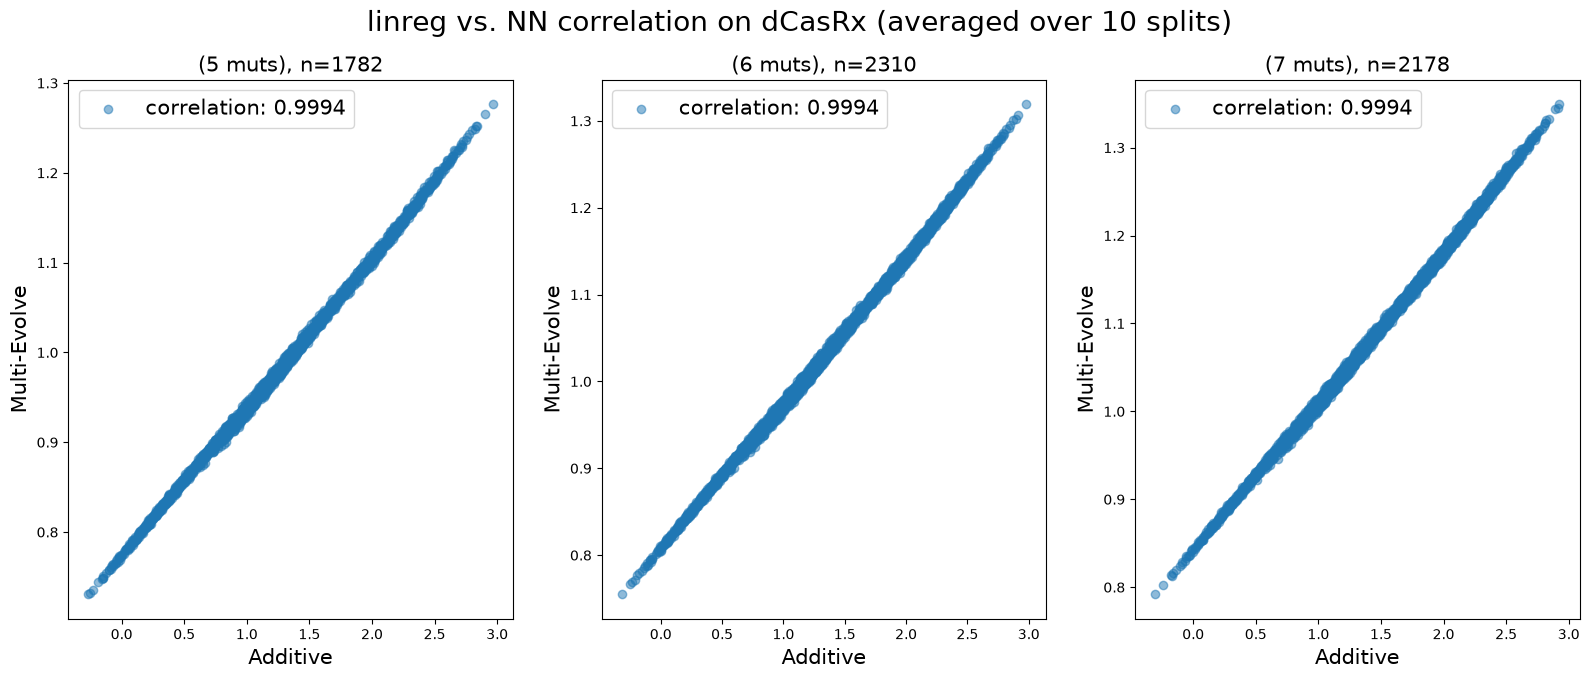

In [20]:
n_panels = len(MUT_COUNTS)
fig, ax = plt.subplots(1, n_panels, figsize=(6.5 * n_panels, 7))
if n_panels == 1:
    ax = [ax]

protein_label = {'apex': 'APEX', 'dcasrx': 'dCasRx', 'huabc2': 'HuABC2'}[PROTEIN]
if PROTEIN == 'huabc2':
    meas_label = 'Expression' if MEASUREMENT == 'expr' else 'Binding'
    protein_label = f'{protein_label} ({meas_label})'

fig.suptitle(f"linreg vs. NN correlation on {protein_label} (averaged over {N_SPLITS} splits)", fontsize=20)

for i, num_muts in enumerate(MUT_COUNTS):
    num_muts_idx = num_muts_per_seq == num_muts
    nn_preds = NN_vals[num_muts_idx]
    linreg_preds = linreg_vals[num_muts_idx]

    correlation = np.corrcoef(nn_preds, linreg_preds)[0, 1]
    ax[i].set_title(f"({num_muts} muts), n={nn_preds.shape[0]}", fontsize=15)
    ax[i].scatter(linreg_preds, nn_preds, label="correlation: %.4f" % correlation, alpha=0.5)
    ax[i].set_ylabel("Multi-Evolve", fontsize=15)
    ax[i].set_xlabel("Additive", fontsize=15)
    ax[i].legend(loc="upper left", fontsize=15)

plt.show()

## Beginning interp

In [21]:
# Weight analysis uses models[0] as a representative split
# print(models[0])

In [22]:
from matplotlib import colormaps
import matplotlib as mpl

In [23]:
# print(models[0].layers[0].weight)

In [24]:
# col_mean = models[0].layers[0].weight.abs().mean(dim=0)
# fig, ax = plt.subplots(1,1,figsize=(14,10))
# counts, bins, _ = ax.hist(col_mean.cpu().numpy(), bins=100)
# bins = bins[1:]

# ticklabels = [x*0.015 for x in range(12)]
# disp_ticklabels = []
# for s in ticklabels:
#     idx = np.logical_and(bins <= s, bins > s - 0.02)
#     disp_ticklabels.append(counts[idx].sum().astype(int))

# ax.set_ylim([0,50])
# ax.set_xticks(ticklabels)
# ax.set_xticklabels([f"%.3f\nn=%d"%(s,n) for s,n in zip(ticklabels, disp_ticklabels)])
# ax.set_title("histogram of column norms -- MLP W_in (split 0)",fontsize=20)
# plt.show()

In [25]:
# print(col_mean[:22])
# fig,ax=plt.subplots(1,1,figsize=(14,10))
# im = ax.matshow(col_mean[22:].view((22*6, 161)).cpu(), cmap=mpl.cm.Greys)
# ax.set_title("column norm heatmap (split 0)", fontsize=20)
# fig.colorbar(im)
# plt.show()

# print(torch.argwhere(col_mean >= 0.007).squeeze())
# print(torch.argwhere(col_mean >= 0.007).squeeze().shape)

In [26]:
# fig, ax = plt.subplots(20,1,figsize=(10,30))
# for i in range(20):
#     im = ax[i].matshow(models[0].layers[0].weight[:, 800*i:800*(i+1)].cpu(), cmap=mpl.cm.RdBu, vmin=-0.1, vmax=0.1)

# fig.subplots_adjust(right=0.8)
# cbar_ax = fig.add_axes([0.85, 0.15, 0.05, 0.7])
# fig.colorbar(im, cax=cbar_ax)
# fig.suptitle("W_in weight matrix (split 0)", fontsize=16, y=0.92)
# plt.show()

## Examining whether NN learns any epistatic effects:

### Given mutations $\{m_1,...,m_N\}$ that appear in our doubles dataset, we use the following notation: 
$\begin{cases}y_i := \text{logfc for variant w/ mutation } m_i \\ 
y_{ij} := \text{logfc for variant w/ mutations } m_i, m_j \\
\hat{y}_i := \text{FCN score for variant w/ mutation } m_i \\ 
\hat{y}_{ij} := \text{FCN score for variant w/ mutation } m_i, m_j\end{cases}$


### Then, for each pair of $(m_i, m_j)$, we compare $(\hat{y}_{ij} - (\hat{y}_i + \hat{y}_j))$ vs. $(y_{ij} - (y_i + y_j))$

In [27]:
single_data = full_df[full_df['Origin'].isin(['DMS', 'PLM zeroshot'])].copy()
double_data = full_df[full_df['Origin'] == 'Double Mutant'].copy()

muts = np.array(double_data[MUTANT_COL])

In [28]:
data_residuals = []

for m1m2 in muts:
    if IS_MULTICHAIN:
        # Decompose chain-notation double → two chain-notation singles
        sings = double_to_singles(m1m2)
        if len(sings) != 2:
            data_residuals.append(np.nan)
            continue
        m1, m2 = sings
        yi_row = single_data[single_data[MUTANT_COL] == m1]['logfc']
        yj_row = single_data[single_data[MUTANT_COL] == m2]['logfc']
        if len(yi_row) == 0 or len(yj_row) == 0:
            data_residuals.append(np.nan)
            continue
        yi = yi_row.item()
        yj = yj_row.item()
    else:
        m1, m2 = m1m2.split("/")
        yi = single_data[single_data[MUTANT_COL] == m1]["logfc"].item()
        yj = single_data[single_data[MUTANT_COL] == m2]["logfc"].item()

    yij = double_data[double_data[MUTANT_COL] == m1m2]["logfc"].item()
    data_residuals.append(yij - (yi + yj))

data_residuals = np.array(data_residuals)
# Drop any NaN entries (only possible for huabc2 if singles are missing)
valid_mask = ~np.isnan(data_residuals)
print(f"Data residuals: {valid_mask.sum()} valid / {len(data_residuals)} total")

Data residuals: 95 valid / 95 total


In [29]:
# Average NN residuals over all splits
if IS_MULTICHAIN:
    # Build all sequences: for each double, the double + two singles
    all_seqs = []
    seq_map = []  # indices into muts
    valid_muts = muts[valid_mask]
    for i, m1m2 in enumerate(valid_muts):
        sings = double_to_singles(m1m2)
        all_seqs.append(apply_chain_mutations(m1m2))
        all_seqs.append(apply_chain_mutations(sings[0]))
        all_seqs.append(apply_chain_mutations(sings[1]))

    all_enc = models[0].featurizer.featurize(all_seqs)
    all_tensor = torch.from_numpy(all_enc).float().to(device)

    all_split_residuals = []
    for m in models:
        m.eval()
        preds = m(all_tensor).squeeze().cpu().numpy()
        split_res = []
        for i in range(len(valid_muts)):
            yhat_ij = preds[3 * i]
            yhat_i  = preds[3 * i + 1]
            yhat_j  = preds[3 * i + 2]
            split_res.append(yhat_ij - (yhat_i + yhat_j))
        all_split_residuals.append(split_res)

    all_split_residuals = np.array(all_split_residuals)
    nn_residuals = all_split_residuals.mean(axis=0)
    # Also filter data_residuals to valid only
    data_residuals_valid = data_residuals[valid_mask]
else:
    all_split_residuals = []
    for m in models:
        m.eval()
        split_residuals = []
        for m1m2 in muts:
            m1, m2 = m1m2.split("/")
            _, fcn_data = Ldata_to_NNdata(
                build_onehot([m1m2, m1, m2], mut_to_index, len(mut_to_index)),
                wt_seq,
                m.featurizer,
            )
            fcn_vals = m(torch.from_numpy(fcn_data).float().to(device))
            split_residuals.append((fcn_vals[0] - (fcn_vals[1] + fcn_vals[2])).item())
        all_split_residuals.append(split_residuals)

    all_split_residuals = np.array(all_split_residuals)
    nn_residuals = all_split_residuals.mean(axis=0)
    data_residuals_valid = data_residuals

print(f"Averaged NN residuals over {len(models)} splits, n={len(nn_residuals)}")

Averaged NN residuals over 10 splits, n=95


In [30]:
# Average NN intercept (WT prediction) over all splits
nn_intercepts = []
for m in models:
    m.eval()
    if IS_MULTICHAIN:
        wt_enc = m.featurizer.featurize([wt_seq])
        fcn_vals = m(torch.from_numpy(wt_enc).float().to(device))
    else:
        _, fcn_data = Ldata_to_NNdata(
            build_onehot([""], mut_to_index, len(mut_to_index)),
            wt_seq,
            m.featurizer,
        )
        fcn_vals = m(torch.from_numpy(fcn_data).float().to(device))
    nn_intercepts.append(fcn_vals[0][0].item())

nn_intercept = np.mean(nn_intercepts)
print(f"NN intercept (avg over {len(models)} splits): {nn_intercept:.6f}")
print(f"  per-split: {[f'{v:.4f}' for v in nn_intercepts]}")

NN intercept (avg over 10 splits): 0.682160
  per-split: ['0.6696', '0.7299', '0.6932', '0.6619', '0.6350', '0.6280', '0.7049', '0.7003', '0.7391', '0.6600']


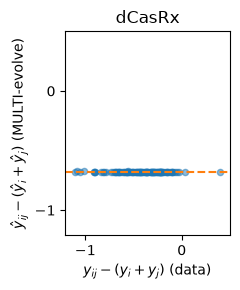

In [31]:
from matplotlib import ticker


protein_label = {'apex': 'APEX', 'dcasrx': 'dCasRx', 'huabc2': 'HuABC2'}[PROTEIN]
if PROTEIN == 'huabc2':
    protein_label = f'{protein_label} ({MEASUREMENT})'

meas_tag = f'_{MEASUREMENT}' if PROTEIN == 'huabc2' else ''

plt.figure(figsize=(2.5, 3))
plt.scatter(data_residuals_valid, nn_residuals, s=20, alpha=0.5)
plt.xlabel("$y_{ij} - (y_i + y_j)$ (data)")
plt.ylabel("$\hat y_{ij} - (\hat y_i + \hat y_j)$ (MULTI-evolve)")
all_vals = np.concatenate([data_residuals_valid, nn_residuals])
plt.xlim(all_vals.min() - 0.1, all_vals.max() + 0.1)
plt.ylim(all_vals.min() - 0.1, all_vals.max() + 0.1)
plt.axhline(-nn_intercept, color='C1', linestyle='--')
plt.gca().xaxis.set_major_locator(ticker.MaxNLocator(integer=True))
plt.gca().yaxis.set_major_locator(ticker.MaxNLocator(integer=True))
# plt.legend()
plt.title(protein_label)
plt.tight_layout()
plt.savefig(f"../figures/{PROTEIN}{meas_tag}_data_vs_nn_epistasis.pdf")
plt.show()